# Level 3 · Task 2 — Customer Preference Analysis
**Cognifyz Data Science Internship**

**Goals**
1. Analyze the relationship between cuisine type and restaurant rating.
2. Identify the most popular cuisines by number of votes.
3. Determine whether specific cuisines tend to receive higher ratings.

**Method notes**
- `Cuisines` is multi-valued (e.g. "French, Japanese, Desserts"), so it is split and **exploded**: a restaurant counts once toward each cuisine it lists.
- Rating `0` means *Not rated*; it is excluded from all rating statistics (but kept for vote totals).
- Cuisines with few rated restaurants give unreliable averages, so rating rankings require a minimum sample size (`MIN_RESTAURANTS`).
- Because cuisine mix differs by country and countries rate differently, a **country-adjusted** rating is reported alongside the raw average.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline

RANDOM_STATE = 42
DATA_PATH = Path("../dataset/Dataset.csv")
TARGET = "Aggregate rating"
MIN_RESTAURANTS = 30   # minimum rated restaurants for a cuisine to enter rating rankings
TOP_N = 15

# Country codes -> names (the dataset only provides codes; mapping checked against the cities in the data).
COUNTRY_NAMES = {
    1: "India", 14: "Australia", 30: "Brazil", 37: "Canada", 94: "Indonesia",
    148: "New Zealand", 162: "Philippines", 166: "Qatar", 184: "Singapore",
    189: "South Africa", 191: "Sri Lanka", 208: "Turkey", 214: "UAE",
    215: "United Kingdom", 216: "United States",
}

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")

## 1. Load data and build the cuisine-level table

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. Expected layout: "
        "Cognifyz_Internship/Dataset/Dataset.csv with this notebook in Cognifyz_Internship/Level3/."
    )

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.columns = df.columns.str.strip()
df["Country"] = df["Country Code"].map(COUNTRY_NAMES).fillna(df["Country Code"].astype(str))

print(f"Rows: {len(df):,} | missing Cuisines: {df['Cuisines'].isna().sum()} (excluded from cuisine analysis)")
print(f"Not rated (rating 0): {(df[TARGET] == 0).sum():,} | max votes among them: {df.loc[df[TARGET] == 0, 'Votes'].max()}")

rated = df[df[TARGET] > 0].copy()

cuisine_long = (
    df.dropna(subset=["Cuisines"])
    .assign(Cuisine=lambda d: d["Cuisines"].str.split(","))
    .explode("Cuisine")
)
cuisine_long["Cuisine"] = cuisine_long["Cuisine"].str.strip()
cuisine_long = cuisine_long[cuisine_long["Cuisine"] != ""].drop_duplicates(["Restaurant ID", "Cuisine"])

# Country-adjusted rating: rating minus the mean rating of rated restaurants in the same country.
country_mean = rated.groupby("Country Code")[TARGET].mean()
cuisine_long["Country Mean"] = cuisine_long["Country Code"].map(country_mean)
cuisine_long["Adj Rating"] = cuisine_long[TARGET] - cuisine_long["Country Mean"]

rated_long = cuisine_long[cuisine_long[TARGET] > 0]
print(f"Distinct cuisines: {cuisine_long['Cuisine'].nunique()} | exploded rows: {len(cuisine_long):,}")

Rows: 9,551 | missing Cuisines: 9 (excluded from cuisine analysis)
Not rated (rating 0): 2,148 | max votes among them: 3
Distinct cuisines: 145 | exploded rows: 19,705


In [3]:
pop = cuisine_long.groupby("Cuisine").agg(
    restaurants=("Restaurant ID", "nunique"),
    total_votes=("Votes", "sum"),
)
rat = rated_long.groupby("Cuisine").agg(
    rated_restaurants=(TARGET, "size"),
    avg_rating=(TARGET, "mean"),
    median_rating=(TARGET, "median"),
    std_rating=(TARGET, "std"),
    avg_votes=("Votes", "mean"),
    adj_rating=("Adj Rating", "mean"),
)
summary = pop.join(rat, how="left")
summary["rated_restaurants"] = summary["rated_restaurants"].fillna(0).astype(int)
eligible = summary[summary["rated_restaurants"] >= MIN_RESTAURANTS].copy()
print(f"{len(eligible)} of {len(summary)} cuisines have >= {MIN_RESTAURANTS} rated restaurants.")

39 of 145 cuisines have >= 30 rated restaurants.


## 2. Most popular cuisines (by number of votes)
"Share of all votes" is the fraction of total votes cast on restaurants that list the cuisine; because restaurants can
list several cuisines, the shares add up to more than 100%.

,restaurants,total_votes,share_of_all_votes,avg_votes,avg_rating
Cuisine,,,,,
North Indian,3960,595981,0.398,197.280,3.295
Chinese,2733,363879,0.243,166.553,3.282
Italian,764,329265,0.220,453.485,3.748
Continental,736,288255,0.192,412.322,3.705
Fast Food,1986,184058,0.123,117.508,3.257
American,390,183117,0.122,481.858,3.758
Cafe,703,177568,0.118,279.959,3.683
Mughlai,994,151944,0.101,191.164,3.271
Desserts,653,105889,0.071,194.808,3.582


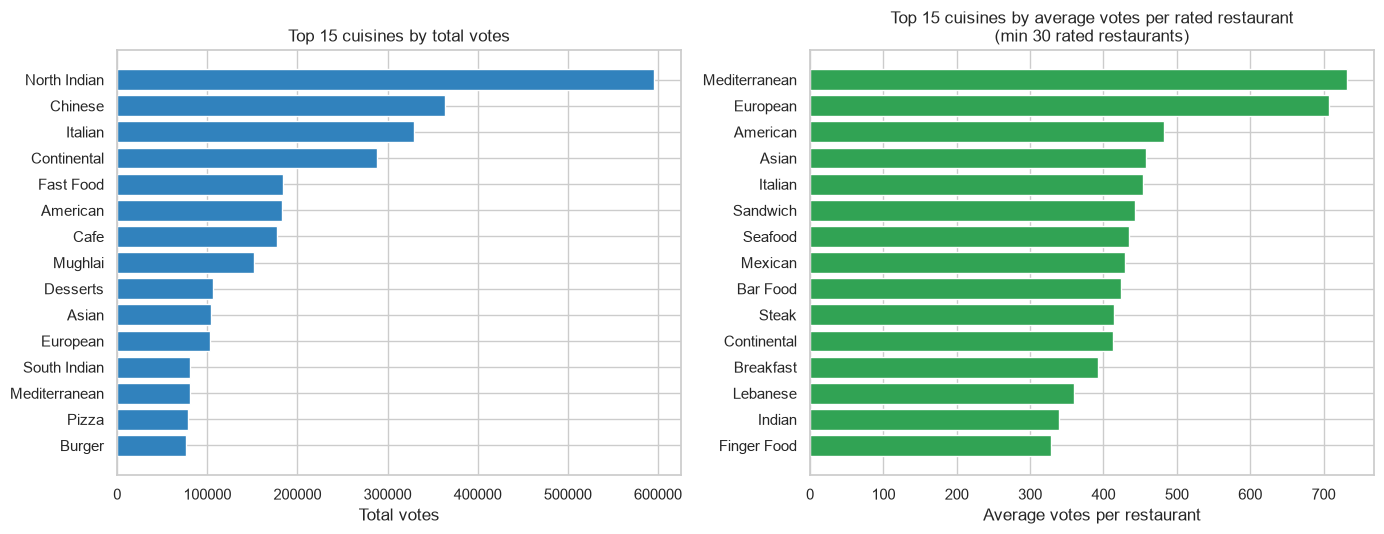

In [4]:
total_votes_all = df["Votes"].sum()
top_votes = summary.sort_values("total_votes", ascending=False).head(TOP_N).copy()
top_votes["share_of_all_votes"] = top_votes["total_votes"] / total_votes_all
display(top_votes[["restaurants", "total_votes", "share_of_all_votes", "avg_votes", "avg_rating"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
d = top_votes.sort_values("total_votes")
axes[0].barh(d.index, d["total_votes"], color="#3182bd")
axes[0].set(title=f"Top {TOP_N} cuisines by total votes", xlabel="Total votes")

by_avg = eligible.sort_values("avg_votes", ascending=False).head(TOP_N).sort_values("avg_votes")
axes[1].barh(by_avg.index, by_avg["avg_votes"], color="#31a354")
axes[1].set(title=f"Top {TOP_N} cuisines by average votes per rated restaurant\n(min {MIN_RESTAURANTS} rated restaurants)",
            xlabel="Average votes per restaurant")
plt.tight_layout()
plt.show()

Total votes reward *volume* (many restaurants serve the cuisine); average votes per restaurant show which cuisines
draw the most engagement **per venue**. Both views are shown because they answer different questions.

## 3. Do some cuisines receive higher ratings?
For every cuisine with enough data: mean rating with a 95% confidence interval, and a Welch t-test of its restaurants
against all other rated restaurants. Because many cuisines are tested at once, p-values are adjusted with the
Benjamini-Hochberg false-discovery-rate procedure.

In [5]:
def benjamini_hochberg(p_values):
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    order = np.argsort(p)
    scaled = p[order] * n / np.arange(1, n + 1)
    adjusted = np.minimum.accumulate(scaled[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.clip(adjusted, 0, 1)
    return out


tests = []
for cuisine in eligible.index:
    mask = rated_long["Cuisine"] == cuisine
    a = rated_long.loc[mask, TARGET]
    ids = set(rated_long.loc[mask, "Restaurant ID"])
    b = rated.loc[~rated["Restaurant ID"].isin(ids), TARGET]
    t_stat, p_val = stats.ttest_ind(a, b, equal_var=False)
    tests.append({
        "Cuisine": cuisine,
        "ci95": 1.96 * a.std(ddof=1) / np.sqrt(len(a)),
        "diff_vs_rest": a.mean() - b.mean(),
        "p_value": p_val,
    })

tests = pd.DataFrame(tests).set_index("Cuisine")
tests["q_value (FDR)"] = benjamini_hochberg(tests["p_value"])
eligible = eligible.join(tests)
eligible["significant (q<0.05)"] = eligible["q_value (FDR)"] < 0.05

overall_mean = rated[TARGET].mean()
print(f"Overall mean rating (rated restaurants): {overall_mean:.3f}")

cols = ["rated_restaurants", "avg_rating", "ci95", "diff_vs_rest", "q_value (FDR)", "significant (q<0.05)"]
print(f"\nHighest-rated cuisines (min {MIN_RESTAURANTS} rated restaurants):")
display(eligible.sort_values("avg_rating", ascending=False).head(10)[cols])
print("Lowest-rated cuisines:")
display(eligible.sort_values("avg_rating").head(10)[cols])

Overall mean rating (rated restaurants): 3.440

Highest-rated cuisines (min 30 rated restaurants):


,rated_restaurants,avg_rating,ci95,diff_vs_rest,q_value (FDR),significant (q<0.05)
Cuisine,,,,,,
Indian,66,4.156,0.116,0.722,0.000,True
Bar Food,37,4.146,0.149,0.709,0.000,True
Sandwich,53,4.066,0.136,0.631,0.000,True
BBQ,32,4.025,0.157,0.588,0.000,True
Mediterranean,110,4.020,0.077,0.589,0.000,True
Steak,62,3.985,0.101,0.550,0.000,True
Sushi,75,3.973,0.083,0.539,0.000,True
Breakfast,41,3.966,0.135,0.529,0.000,True
European,146,3.964,0.082,0.535,0.000,True


Lowest-rated cuisines:


,rated_restaurants,avg_rating,ci95,diff_vs_rest,q_value (FDR),significant (q<0.05)
Cuisine,,,,,,
Raw Meats,80,3.067,0.053,-0.377,0.000,True
Mithai,251,3.139,0.049,-0.311,0.000,True
Salad,91,3.235,0.115,-0.207,0.001,True
South Indian,485,3.239,0.043,-0.215,0.000,True
Fast Food,1563,3.257,0.023,-0.232,0.000,True
Mughlai,794,3.271,0.034,-0.190,0.000,True
Chinese,2182,3.282,0.021,-0.224,0.000,True
Street Food,403,3.286,0.046,-0.163,0.000,True
North Indian,3017,3.295,0.018,-0.245,0.000,True


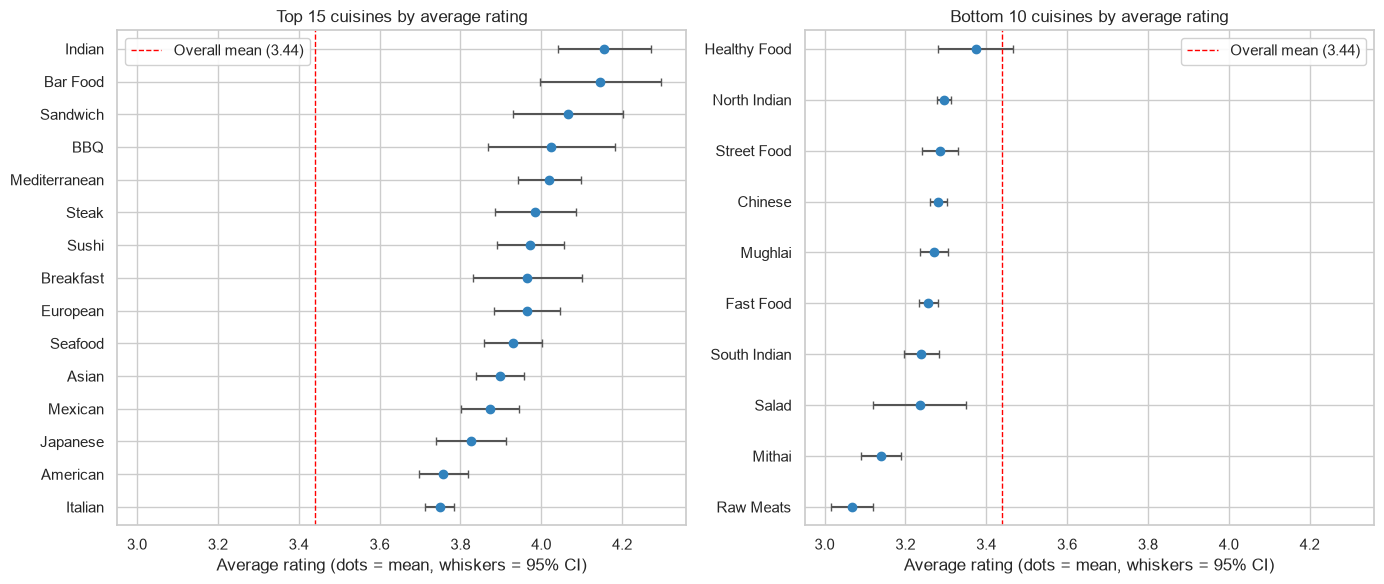

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, (title, frame) in zip(
    axes,
    [
        (f"Top {TOP_N} cuisines by average rating", eligible.sort_values("avg_rating", ascending=False).head(TOP_N)),
        ("Bottom 10 cuisines by average rating", eligible.sort_values("avg_rating").head(10)),
    ],
):
    frame = frame.sort_values("avg_rating")
    ax.errorbar(frame["avg_rating"], frame.index, xerr=frame["ci95"], fmt="o", color="#3182bd",
                ecolor="#555", capsize=3, markersize=6)
    ax.axvline(overall_mean, color="red", ls="--", lw=1, label=f"Overall mean ({overall_mean:.2f})")
    ax.set(title=title, xlabel="Average rating (dots = mean, whiskers = 95% CI)")
    ax.margins(y=0.04)
    ax.legend(loc="best", framealpha=0.9)
plt.tight_layout()
plt.show()

### Popularity vs. rating
Does being popular (many restaurants) go together with a higher or lower average rating?

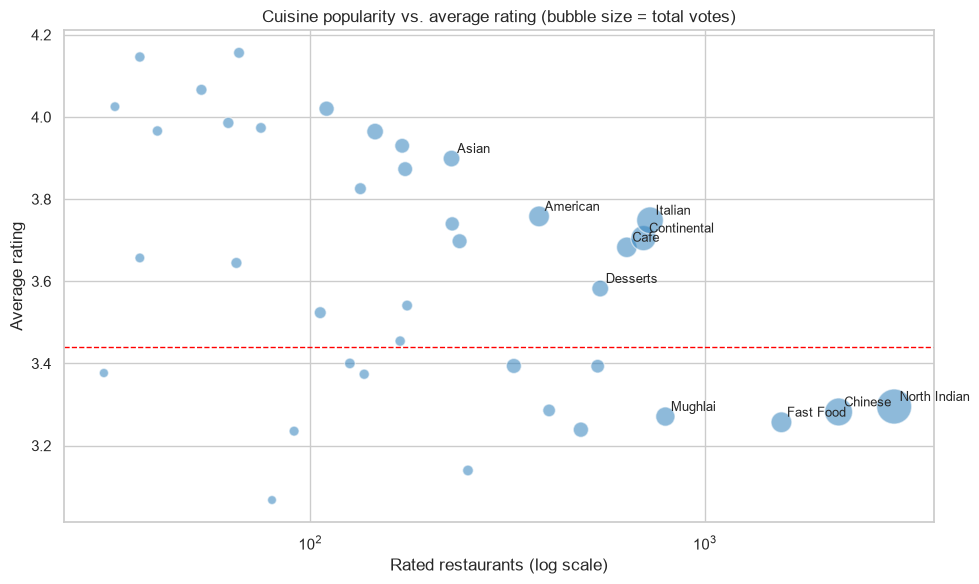

Spearman correlation (restaurant count vs avg rating): rho = -0.467, p = 0.00272


In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
sizes = 40 + 600 * eligible["total_votes"] / eligible["total_votes"].max()
ax.scatter(eligible["rated_restaurants"], eligible["avg_rating"], s=sizes, alpha=0.55, color="#3182bd", edgecolor="white")
ax.set_xscale("log")
ax.axhline(overall_mean, color="red", ls="--", lw=1)
for name in eligible.sort_values("total_votes", ascending=False).head(10).index:
    ax.annotate(name, (eligible.loc[name, "rated_restaurants"], eligible.loc[name, "avg_rating"]),
                xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.set(title="Cuisine popularity vs. average rating (bubble size = total votes)",
       xlabel="Rated restaurants (log scale)", ylabel="Average rating")
plt.tight_layout()
plt.show()

rho, p_rho = stats.spearmanr(eligible["rated_restaurants"], eligible["avg_rating"])
print(f"Spearman correlation (restaurant count vs avg rating): rho = {rho:.3f}, p = {p_rho:.3g}")

### Rating distributions for the most-voted cuisines

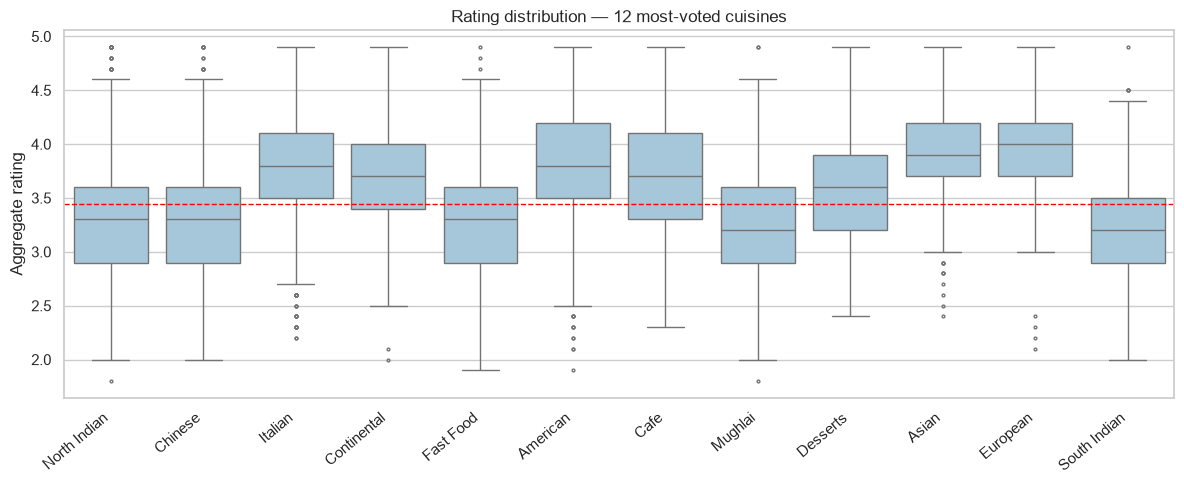

In [8]:
top_names = list(summary.sort_values("total_votes", ascending=False).head(12).index)
plot_data = rated_long[rated_long["Cuisine"].isin(top_names)]
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=plot_data, x="Cuisine", y=TARGET, order=top_names, color="#9ecae1", fliersize=2, ax=ax)
ax.axhline(overall_mean, color="red", ls="--", lw=1)
ax.set(title="Rating distribution — 12 most-voted cuisines", xlabel="", ylabel=TARGET)
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
plt.tight_layout()
plt.show()

## 4. Controlling for country
The dataset is dominated by one country, and countries differ in their rating levels. A cuisine concentrated in
a high- or low-rating country can look good or bad for that reason alone. The **adjusted rating** subtracts the
country mean from each restaurant's rating before averaging by cuisine.

Highest country-adjusted rating:


,rated_restaurants,avg_rating,adj_rating
Cuisine,,,
Mediterranean,110,4.020,0.534
European,146,3.964,0.451
Asian,228,3.899,0.388
Continental,699,3.705,0.341
Italian,726,3.748,0.313
Mexican,174,3.873,0.311
Thai,229,3.740,0.295
Tea,37,3.657,0.247
Lebanese,65,3.645,0.242


Lowest country-adjusted rating:


,rated_restaurants,avg_rating,adj_rating
Cuisine,,,
Raw Meats,80,3.067,-0.285
Mithai,251,3.139,-0.213
Salad,91,3.235,-0.124
South Indian,485,3.239,-0.122
Fast Food,1563,3.257,-0.106
Pizza,328,3.394,-0.105
Mughlai,794,3.271,-0.085
Chinese,2182,3.282,-0.084
Street Food,403,3.286,-0.083


Rank correlation between raw and adjusted cuisine rating: 0.623


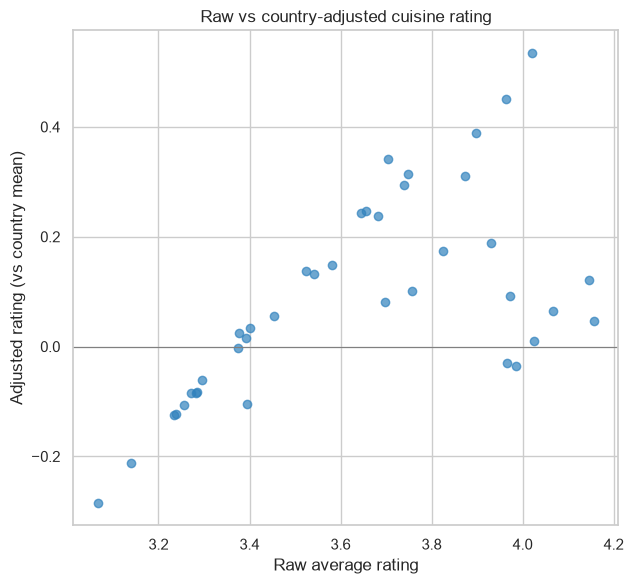

In [9]:
adj_cols = ["rated_restaurants", "avg_rating", "adj_rating"]
print("Highest country-adjusted rating:")
display(eligible.sort_values("adj_rating", ascending=False).head(10)[adj_cols])
print("Lowest country-adjusted rating:")
display(eligible.sort_values("adj_rating").head(10)[adj_cols])

rho_adj, _ = stats.spearmanr(eligible["avg_rating"], eligible["adj_rating"])
print(f"Rank correlation between raw and adjusted cuisine rating: {rho_adj:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(eligible["avg_rating"], eligible["adj_rating"], alpha=0.7, color="#3182bd")
ax.axhline(0, color="gray", lw=0.8)
ax.set(title="Raw vs country-adjusted cuisine rating", xlabel="Raw average rating", ylabel="Adjusted rating (vs country mean)")
plt.tight_layout()
plt.show()

## 5. How much of the rating does cuisine explain?
A cross-validated Ridge regression predicts a restaurant's rating from (a) its cuisines only (multi-hot, 40 most
frequent), (b) its country only, and (c) both. Comparing the R² values shows how much cuisine adds.

In [10]:
def split_cuisines(text):
    return [c.strip() for c in text.split(",") if c.strip()]


modeled = rated.dropna(subset=["Cuisines"]).reset_index(drop=True)
vocab = list(summary.sort_values("restaurants", ascending=False).head(40).index)
cv_vec = CountVectorizer(vocabulary=vocab, tokenizer=split_cuisines, token_pattern=None, lowercase=False, binary=True)
# Cast to float: integer input makes RidgeCV truncate its intercept in some sklearn versions.
X_cuisine = cv_vec.fit_transform(modeled["Cuisines"]).toarray().astype(float)
X_country = pd.get_dummies(modeled["Country"]).to_numpy(dtype=float)
y = modeled[TARGET].to_numpy()

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for label, X in [("Cuisine only", X_cuisine), ("Country only", X_country),
                 ("Country + cuisine", np.hstack([X_country, X_cuisine]))]:
    scores = cross_val_score(make_pipeline(RidgeCV(alphas=np.logspace(-2, 3, 12))), X, y, cv=cv, scoring="r2")
    rows.append({"Features": label, "CV R2 (mean)": scores.mean(), "CV R2 (std)": scores.std()})
explained = pd.DataFrame(rows)
display(explained)

,Features,CV R2 (mean),CV R2 (std)
0,Cuisine only,0.248,0.022
1,Country only,0.193,0.008
2,Country + cuisine,0.325,0.012


## 6. Summary

In [11]:
top_pop = summary.sort_values("total_votes", ascending=False).iloc[0]
best = eligible.sort_values("avg_rating", ascending=False).iloc[0]
worst = eligible.sort_values("avg_rating").iloc[0]
n_sig_up = int(((eligible["q_value (FDR)"] < 0.05) & (eligible["diff_vs_rest"] > 0)).sum())
n_sig_down = int(((eligible["q_value (FDR)"] < 0.05) & (eligible["diff_vs_rest"] < 0)).sum())

print(f"Most-voted cuisine: {summary['total_votes'].idxmax()} "
      f"({int(top_pop['total_votes']):,} votes across {int(top_pop['restaurants']):,} restaurants)")
print(f"Highest average rating (min {MIN_RESTAURANTS} rated): {eligible['avg_rating'].idxmax()} "
      f"({best['avg_rating']:.2f}, n={int(best['rated_restaurants'])}); "
      f"lowest: {eligible['avg_rating'].idxmin()} ({worst['avg_rating']:.2f}, n={int(worst['rated_restaurants'])})")
print(f"Cuisines tested: {len(eligible)} | significantly above the rest (FDR 5%): {n_sig_up} | significantly below: {n_sig_down}")
r_c = explained.set_index("Features")["CV R2 (mean)"]
print(f"Variance explained (CV R2): cuisine only {r_c['Cuisine only']:.3f}, country only {r_c['Country only']:.3f}, "
      f"both {r_c['Country + cuisine']:.3f}")

Most-voted cuisine: North Indian (595,981 votes across 3,960 restaurants)
Highest average rating (min 30 rated): Indian (4.16, n=66); lowest: Raw Meats (3.07, n=80)
Cuisines tested: 39 | significantly above the rest (FDR 5%): 23 | significantly below: 10
Variance explained (CV R2): cuisine only 0.248, country only 0.193, both 0.325


**Notes and limitations**
- Ratings are observational and self-selected; differences between cuisines are associations, not proof that a cuisine "causes" higher ratings.
- Cuisine averages are computed per cuisine tag, so multi-cuisine restaurants contribute to several cuisines and the groups overlap.
- Cuisines below the minimum sample size are excluded from rating rankings because their averages are unstable.
- Country-level adjustment removes country rating differences but not city, price, or venue-type effects.